# Analisis Exploratorio de Datos (EDA)
# Evaluaciones Agropecuarias Municipales (EVA)

**Inteligencia Artificial I — Grupo C2, Periodo 2026-2**

Profesor: Santiago Gomez


**Variable objetivo: Area cosechada (hectareas)**

---

### Enlace publico a este Colab
Pegar aqui el enlace del notebook (requisito para poder presentar):
`https://colab.research.google.com/drive/XXXXXXXXXX`

### Integrantes

| Nombre | Codigo |
|---|---|
| Iván | 2234685 |
| Yerson | 2234675 |
| Cristian Gutierrez | 2230040 |
| David | 2221897  |

---

### Contenido

1. Problema y datos
2. Justificacion del uso de Inteligencia Artificial
3. Limpieza y union de los dos archivos
4. Variable objetivo: Area cosechada
5. Analisis de distribuciones de las demas variables
6. Calidad de datos y patrones encontrados
7. Conclusiones y proximos pasos

### Herramientas usadas
Python, NumPy, Pandas, Matplotlib, Seaborn y Plotly.

---
# 1. Problema y datos

## 1.1 De donde salen los datos

Los datos vienen de las **Evaluaciones Agropecuarias Municipales (EVA)**, el registro oficial
con el que el Estado colombiano mide, municipio por municipio, cuanto se siembra, se cosecha y
se produce en el pais. La informacion la levantan las Secretarias de Agricultura departamentales
y las UMATA (Unidades Municipales de Asistencia Tecnica Agropecuaria) en cada municipio, y la
consolida la **Unidad de Planificacion Rural Agropecuaria (UPRA)** por delegacion del
**Ministerio de Agricultura y Desarrollo Rural** (Resolucion 299 de 2019). Se publica en el
portal de datos abiertos del Estado, datos.gov.co ([UPRA — EVA](https://upra.gov.co/en/eva);
[datos.gov.co — EVA](https://www.datos.gov.co/Agricultura-y-Desarrollo-Rural/Evaluaciones-Agropecuarias-Municipales-EVA-2019-20/uejq-wxrr)).

Trabajamos con dos archivos que traen la misma informacion en periodos distintos, y que unimos
en una sola tabla (ver seccion 3):

| Archivo | Anios | Filas aproximadas |
|---|---|---|
| EVA_2007_2018.csv | 2006 - 2018 | 206.000 |
| EVA_2019_2025.csv | 2019 - 2025 | 167.000 |

Despues de unirlos y limpiarlos queda una tabla de mas de **370.000 filas**, con **32
departamentos**, **1.059 municipios** y **248 cultivos** distintos. Cada fila representa: un
municipio, un cultivo y un periodo (semestre A, semestre B o reporte anual).

## 1.2 Por que Area sembrada y Area cosechada no son lo mismo

El DANE y el Ministerio de Agricultura definen estas dos variables de forma distinta, y esa
diferencia es justamente lo que este proyecto busca predecir:

- **Area sembrada**: "el area cultivada con una determinada planta o asocio de plantas en forma
  compacta para ser cosechada durante los periodos de referencia de la encuesta" (MADR & DANE,
  2001, citado en [DANE — Metodologia ENA](https://www.dane.gov.co/files/operaciones/ENA/met-ENA-mar2023.pdf)).
- **Area cosechada**: "el area total en la que se ha recolectado el cultivo; **se excluye el
  area destruida por sequias, inundaciones, plagas o cualquier otra razon**" (FAO, 2016, citado
  en el mismo documento del DANE).

En otras palabras: no toda el area que se siembra se termina cosechando. La diferencia entre las
dos es la **perdida de cosecha**, y refleja el riesgo real que corre un cultivo entre que se
siembra y se recoge: clima adverso, plagas, o que al productor no le convenga cosechar porque el
precio de venta no cubre el costo. El DANE incluso reporta estas perdidas en un anexo aparte de
la Encuesta Nacional Agropecuaria
([DANE — Perdidas de cosecha de cultivos](https://www.dane.gov.co/files/investigaciones/agropecuario/enda/ena/2019/anexo_ena_2019_perdidas_cosechas_cultivos.xlsx)).

## 1.3 Pregunta problema

> **¿Es posible predecir, con datos historicos, cuantas hectareas de un cultivo especifico se
> van a cosechar efectivamente en un municipio colombiano, dado lo que se sembro y el
> comportamiento de periodos anteriores?**

## 1.4 Por que es importante

1. **Seguridad alimentaria y planeacion de oferta.** La EVA es el insumo central que usa el
   Ministerio de Agricultura para estimar cuanto se va a producir en el pais. Anticipar cuanta
   area se va a cosechar de verdad — no solo cuanta se sembro — ayuda a estimar la oferta real de
   alimentos, algo cada vez mas relevante frente a los riesgos de inseguridad alimentaria
   asociados al cambio climatico en Colombia
   ([Impacto del cambio climatico en la seguridad alimentaria en Colombia, Zenodo, 2024](https://zenodo.org/records/17162818)).
2. **Colombia esta muy expuesta a El Nino y La Nina.** Un estudio del Banco de la Republica
   encontro que entre 2008 y 2018, en los periodos mas fuertes de El Nino (poca lluvia), cerca de
   500 de los 1.120 municipios del pais tuvieron sequia, y en La Nina entre 200 y 400 municipios
   sufrieron exceso de lluvias
   ([Banco de la Republica — Climate Shocks in Colombia's Agricultural Sector](https://www.banrep.gov.co/en/blog/climate-shocks-and-their-effects-colombias-agricultural-sector)).
   Estos choques climaticos son precisamente los que abren la brecha entre area sembrada y area
   cosechada.
3. **Afecta el empleo rural.** El mismo estudio encontro que los meses de lluvia excesiva bajan
   el empleo formal rural en 2.3% en promedio, y los meses muy secos lo suben en 1.7%, mostrando
   que lo que pasa con el area cultivada tiene efectos economicos medibles mas alla de la finca.
4. **Sirve para alertas tempranas.** Si se puede anticipar que el area cosechada de un cultivo va
   a caer en una region, se pueden activar a tiempo creditos, asistencia tecnica o seguros
   agropecuarios, antes de que la perdida ya sea un hecho consumado en las cifras de produccion.

## 1.5 Principales desafios

1. Los dos archivos usan nombres de columnas y categorias distintas (hubo que unificarlos, ver
   seccion 3).
2. Los numeros vienen escritos como texto en formato colombiano (`1.247.206,27`).
3. Hay municipios muy pequenios y municipios muy grandes en la misma tabla — 248 cultivos con
   escalas totalmente distintas (desde huertas caseras hasta miles de hectareas de palma o
   arroz).
4. Hay filas con datos imposibles (por ejemplo, cosechar mas de lo que se sembro), que hay que
   detectar y decidir que hacer con ellas.
5. **El area cosechada depende de eventos que pasan despues de la siembra** (clima, plagas,
   decisiones del productor), asi que el historico de area sembrada por si solo no alcanza para
   predecirla con precision.
6. Posible sub-reporte en los periodos mas recientes por rezago administrativo en la
   consolidacion de la EVA.
7. Riesgo de fuga de informacion: como `Produccion = Rendimiento x Area cosechada`, hay que tener
   cuidado si se usan `Produccion` o `Rendimiento` del mismo periodo como variables predictoras.

## Fuentes

- [UPRA — Evaluaciones Agropecuarias Municipales (EVA)](https://upra.gov.co/en/eva)
- [datos.gov.co — EVA 2019-2025, Base Agricola](https://www.datos.gov.co/Agricultura-y-Desarrollo-Rural/Evaluaciones-Agropecuarias-Municipales-EVA-2019-20/uejq-wxrr)
- [DANE — Metodologia de la Encuesta Nacional Agropecuaria (ENA), marzo 2023](https://www.dane.gov.co/files/operaciones/ENA/met-ENA-mar2023.pdf)
- [DANE — Anexo de perdidas de cosecha de cultivos, ENA 2019](https://www.dane.gov.co/files/investigaciones/agropecuario/enda/ena/2019/anexo_ena_2019_perdidas_cosechas_cultivos.xlsx)
- [Banco de la Republica — Climate Shocks and their Effects on Colombia's Agricultural Sector (2023)](https://www.banrep.gov.co/en/blog/climate-shocks-and-their-effects-colombias-agricultural-sector)
- [Impacto del cambio climatico en la seguridad alimentaria en regiones urbanas de Colombia — Zenodo (2024)](https://zenodo.org/records/17162818)


---
# 2. Justificacion del uso de Inteligencia Artificial

## 2.1 El problema no se resuelve con una formula fija ni con un promedio

A diferencia de `Produccion`, que sale de multiplicar `Rendimiento x Area cosechada`, **no existe
una formula para el area cosechada**: depende de decisiones humanas (cuanto sembrar, si vale la
pena cosechar) y de eventos climaticos y biologicos que cambian de forma no lineal segun el
cultivo, el municipio y la epoca del anio. Ahi es donde la IA aporta algo que un promedio
historico o una regla fija no pueden dar:

1. **Aprende patrones no lineales y estacionales.** El area cosechada depende de muchas cosas al
   tiempo (cultivo, municipio, area sembrada, epoca del anio); un modelo puede combinar esas
   variables de forma que una formula fija no logra representar. Investigaciones colombianas
   recientes ya usaron aprendizaje automatico exitosamente para predecir variables agricolas
   similares, como el rendimiento del cultivo de frijol
   ([Prediccion del rendimiento del frijol en Colombia, ACOFI, 2023](https://acofipapers.org/index.php/eiei/article/download/3773/2570/9596)).
2. **Aprende el riesgo climatico de forma implicita.** Como El Nino y La Nina afectan de forma
   distinta a cada region y cultivo
   ([Banco de la Republica, 2023](https://www.banrep.gov.co/en/blog/climate-shocks-and-their-effects-colombias-agricultural-sector)),
   un modelo entrenado con suficiente historia por municipio y cultivo puede aprender patrones de
   vulnerabilidad climatica sin necesitar datos de clima como variable adicional.
3. **Escala a miles de combinaciones.** Son mas de 370.000 filas, 1.059 municipios y 248
   cultivos. Analizar esto caso por caso no es viable; un modelo de IA puede entrenarse una sola
   vez y generalizar patrones compartidos entre cultivos y municipios parecidos.
4. **Sirve para estimar datos que aun no se reportan.** Los datos se publican con retraso; un
   modelo permite estimar el area cosechada de municipios que todavia no han reportado un
   periodo.
5. **Sirve para detectar errores.** Si un dato se aleja mucho de lo que el modelo esperaria,
   probablemente esta mal digitado (como el caso de la soya de Puerto Gaitan que revisamos en la
   seccion 6).
6. **Permite escoger automaticamente las variables del modelo.** En el curso vimos algoritmos
   geneticos; en la Fase 2 los podemos usar para seleccionar de forma automatica cuales variables
   (departamento, cultivo, ciclo, area sembrada, anio, etc.) le sirven mas al modelo, en vez de
   escogerlas a mano.
7. **Valor practico.** Como se explico en la seccion 1, la variabilidad del area cosechada tiene
   efectos medibles sobre seguridad alimentaria y empleo rural; un modelo que anticipe caidas de
   area cosechada por region/cultivo tendria aplicacion directa en politica agropecuaria, algo
   que un promedio historico simple no puede ofrecer.

## Fuentes

- [Prediccion del rendimiento del cultivo de frijol en Colombia — ACOFI (2023)](https://acofipapers.org/index.php/eiei/article/download/3773/2570/9596)
- [Banco de la Republica — Climate Shocks and their Effects on Colombia's Agricultural Sector (2023)](https://www.banrep.gov.co/en/blog/climate-shocks-and-their-effects-colombias-agricultural-sector)
- [Effects of climate change: A look to Agriculture — Scielo (2018)](http://www.scielo.org.co/scielo.php?script=sci_arttext&pid=S0120-01352018000200079)


---
# 3. Limpieza y union de los dos archivos

El plan de limpieza tiene 6 pasos sencillos:

| Paso | Que hacemos | Por que |
|---|---|---|
| 1 | Cargar los dos archivos desde Google Drive | Estan guardados en la carpeta EVA |
| 2 | Ponerle a las columnas los mismos nombres | Cada archivo usa nombres distintos |
| 3 | Convertir los numeros que vienen como texto | "1.247.206,27" no es un numero para Python |
| 4 | Poner el texto en mayusculas y sin tildes | "Boyaca" y "BOYACA" deben ser lo mismo |
| 5 | Unificar los nombres de los grupos de cultivo | Cada archivo usa una clasificacion distinta |
| 6 | Unir los dos archivos en una sola tabla | Para analizar todo junto |

In [1]:
# =========================================================
# Librerias que vamos a usar
# =========================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Estilo de las graficas (colores y tamanio por defecto)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["font.size"] = 11

VERDE = "#2a9d8f"
NARANJA = "#e76f51"
AZUL = "#264653"

# Para ver bien las tablas
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)

print("Librerias cargadas correctamente")

Librerias cargadas correctamente


In [3]:
# =========================================================
# PASO 1: Cargar los dos archivos desde Google Drive
# =========================================================
print("PASO 1: Cargar los dos archivos desde Google Drive")
# Los archivos deben estar guardados en:  MiUnidad / EVA /
from google.colab import drive
drive.mount("/content/drive")

RUTA = "/content/drive/MyDrive/EVA/"

# Leemos todo como texto (dtype=str) porque los numeros vienen en formato colombiano
# y queremos convertirlos nosotros mismos mas adelante.
eva_viejo = pd.read_csv(RUTA + "EVA_2007_2018.csv", dtype=str)
eva_nuevo = pd.read_csv(RUTA + "EVA_2019_2025.csv", dtype=str)

print("EVA 2007-2018:", eva_viejo.shape[0], "filas y", eva_viejo.shape[1], "columnas")
print("EVA 2019-2025:", eva_nuevo.shape[0], "filas y", eva_nuevo.shape[1], "columnas")

print("PASO 1: Ejecutado correctamente")
print("-------------------------------")
# # Comparamos los nombres de las columnas de los dos archivos
# print("COLUMNAS DEL ARCHIVO VIEJO (2007-2018)")
# for nombre in eva_viejo.columns:
#     print("  -", nombre.replace("\n", " "))

# print()
# print("COLUMNAS DEL ARCHIVO NUEVO (2019-2025)")
# for nombre in eva_nuevo.columns:
#     print("  -", nombre)



# =========================================================
# PASO 2: Ponerle a las columnas los mismos nombres
# =========================================================
print("PASO 2: Ponerle a las columnas los mismos nombres")
nombres_viejo = {
    "DEPARTAMENTO": "departamento",
    "MUNICIPIO": "municipio",
    "GRUPO \nDE CULTIVO": "grupo",
    "CULTIVO": "cultivo",
    "CICLO DE CULTIVO": "ciclo",
    "AÑO": "anio",
    "PERIODO": "periodo",
    "Área Sembrada\n(ha)": "area_sembrada",
    "Área Cosechada\n(ha)": "area_cosechada",
    "Producción\n(t)": "produccion",
    "Rendimiento\n(t/ha)": "rendimiento",
}
nombres_nuevo = {
    "Departamento": "departamento",
    "Municipio": "municipio",
    "Grupo cultivo": "grupo",
    "Cultivo": "cultivo",
    "Ciclo del cultivo": "ciclo",
    "Año": "anio",
    "Periodo": "periodo",
    "Área sembrada": "area_sembrada",
    "Área cosechada": "area_cosechada",
    "Producción": "produccion",
    "Rendimiento": "rendimiento",
}
eva_viejo = eva_viejo.rename(columns=nombres_viejo)
eva_nuevo = eva_nuevo.rename(columns=nombres_nuevo)

columnas = ["departamento", "municipio", "grupo", "cultivo", "ciclo",
            "anio", "periodo", "area_sembrada", "area_cosechada",
            "produccion", "rendimiento"]

eva_viejo = eva_viejo[columnas]
eva_nuevo = eva_nuevo[columnas]
print("PASO 2: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 3: Estandarizar los numeros que vienen como texto
# =========================================================
# En los dos archivos el punto separa los miles y la coma es el decimal.
print("PASO 3: Estandarizar los numeros que vienen como texto")

def convertir_a_numero(columna):
    texto = columna.str.replace(".", "", regex=False)
    texto = texto.str.replace(",", ".", regex=False)
    return pd.to_numeric(texto, errors="coerce")

columnas_numericas = ["anio", "area_sembrada", "area_cosechada", "produccion", "rendimiento"]

for columna in columnas_numericas:
    eva_viejo[columna] = convertir_a_numero(eva_viejo[columna])
    eva_nuevo[columna] = convertir_a_numero(eva_nuevo[columna])

# print("Ejemplo del archivo viejo:")
# print(eva_viejo[["anio", "area_sembrada", "area_cosechada", "produccion"]].head(3))
# print()
# print("Ejemplo del archivo nuevo:")
# print(eva_nuevo[["anio", "area_sembrada", "area_cosechada", "produccion"]].head(3))
print("PASO 3: Ejecutado correctamente")
print("-------------------------------")


# =========================================================
# PASO 4: Poner el texto en mayusculas y sin tildes
# =========================================================
# El archivo viejo escribe "BOYACA" y el nuevo "Boyacá". Si no lo arreglamos,
# Pandas los cuenta como dos departamentos diferentes.
print("PASO 4: Poner el texto en mayusculas y sin tildes")

def limpiar_texto(columna):
    texto = columna.str.upper().str.strip()
    texto = texto.str.normalize("NFKD").str.encode("ascii", errors="ignore").str.decode("utf-8")
    return texto

columnas_texto = ["departamento", "municipio", "grupo", "cultivo", "ciclo"]

for columna in columnas_texto:
    eva_viejo[columna] = limpiar_texto(eva_viejo[columna])
    eva_nuevo[columna] = limpiar_texto(eva_nuevo[columna])

eva_nuevo["departamento"] = eva_nuevo["departamento"].replace(
    "ARCHIPIELAGO DE SAN ANDRES, PROVIDENCIA Y SANTA CATALINA",
    "SAN ANDRES Y PROVIDENCIA")
print("PASO 4: Ejecutado correctamente")
print("-------------------------------")

# ==========================================================================
# PASO 5: Nombres de los grupos de cultivo en cada dataset y estandarización
# ==========================================================================
print("PASO 5: Nombres de los grupos de cultivo en cada dataset y estandarización")

grupos_equivalentes = {
    #diferentes
    "TUBERCULOS Y PLATANOS": "RAICES Y TUBERCULOS",
    "PLANTAS AROMATICAS, CONDIMENTARIAS Y MEDICINALES": "CULTIVOS PARA CONDIMENTOS, BEBIDAS MEDICINALES Y AROMATICAS",
    "OTROS PERMANENTES": "CULTIVOS TROPICALES TRADICIONALES",
    #raros extras
    "FIBRAS": "OTROS",
    "FLORES Y FOLLAJES": "OTROS",
    "FORESTALES": "OTROS",
    "HONGOS": "OTROS",
    "OTROS TRANSITORIOS": "OTROS",
}

# actualizan los grupos en el eva viejo
eva_viejo["grupo"] = eva_viejo["grupo"].replace(grupos_equivalentes)


print("PASO 5: Ejecutado correctamente")
print("-------------------------------")
# =========================================================
# PASO 6: Unir los dos archivos en una sola tabla
# =========================================================

print("PASO 6: Unir los dos archivos en una sola tabla")

# EXTRA: Agregamos una columna para saber de que archivo viene cada fila
eva_viejo["fuente"] = "2007-2018"
eva_nuevo["fuente"] = "2019-2025"

datos = pd.concat([eva_viejo, eva_nuevo], ignore_index=True)

# DIFERENCIACIÓN DE LOS SEMESTRES DE CULTIVO
datos["semestre"] = datos["periodo"].str[4:]
datos["semestre"] = datos["semestre"].replace("", "ANUAL")

print("PASO 6: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 7: Eliminar filas con año 2006
# =========================================================
print("PASO 7: Eliminar filas con año 2006")
print("Cantidad de filas para el anio 2006:", len(datos[datos['anio'] == 2006]))
datos = datos[datos['anio'] != 2006]
print("PASO 7: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 8: Datos faltantes por columna
# =========================================================
# Cuantos valores faltan en cada columna

print("PASO 8: Datos faltantes por columna")
faltantes = datos.isna().sum()
porcentaje_faltantes = (datos.isna().mean() * 100).round(2)

tabla_faltantes = pd.DataFrame({
    "valores_faltantes": faltantes,
    "porcentaje": porcentaje_faltantes
})
tabla_faltantes = tabla_faltantes[tabla_faltantes["valores_faltantes"] > 0]

print("Columnas con datos faltantes:")
print(tabla_faltantes)
print()
print("La variable objetivo (area_cosechada) NO tiene datos faltantes.")

print("PASO 8: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 9: Eliminación de filas repetidas
# =========================================================

print("PASO 9: Eliminación de filas repetidas")
repetidas = datos.duplicated().sum()
print("Filas exactamente iguales:", repetidas)


datos = datos.drop_duplicates()
print()
print("Filas despues de quitar las repetidas:", len(datos))

print("PASO 9: Ejecutado correctamente")
print("-------------------------------")

datos.head()


PASO 1: Cargar los dos archivos desde Google Drive
Mounted at /content/drive
EVA 2007-2018: 206068 filas y 17 columnas
EVA 2019-2025: 166732 filas y 18 columnas
PASO 1: Ejecutado correctamente
-------------------------------
PASO 2: Ponerle a las columnas los mismos nombres
PASO 2: Ejecutado correctamente
-------------------------------
PASO 3: Estandarizar los numeros que vienen como texto
PASO 3: Ejecutado correctamente
-------------------------------
PASO 4: Poner el texto en mayusculas y sin tildes
PASO 4: Ejecutado correctamente
-------------------------------
PASO 5: Nombres de los grupos de cultivo en cada dataset y estandarización
PASO 5: Ejecutado correctamente
-------------------------------
PASO 6: Unir los dos archivos en una sola tabla
PASO 6: Ejecutado correctamente
-------------------------------
PASO 7: Eliminar filas con año 2006
Cantidad de filas para el anio 2006: 4072
PASO 7: Ejecutado correctamente
-------------------------------
PASO 8: Datos faltantes por columna

In [ ]:
datos[(datos["cultivo"] == "SOYA") & (datos["municipio"] == "PUERTO GAITAN")]

,departamento,municipio,grupo,cultivo,ciclo,anio,periodo,area_sembrada,area_cosechada,produccion,rendimiento,fuente,semestre
177579,META,PUERTO GAITAN,LEGUMINOSAS,SOYA,TRANSITORIO,2007,2007B,"1,300.00","1,300.00","3,250.00",2.50,2007-2018,B
177612,META,PUERTO GAITAN,LEGUMINOSAS,SOYA,TRANSITORIO,2008,2008A,"2,000.00","2,000.00","5,000.00",2.50,2007-2018,A
177638,META,PUERTO GAITAN,LEGUMINOSAS,SOYA,TRANSITORIO,2008,2008B,"2,470.00","2,470.00","6,175.00",2.50,2007-2018,B
177666,META,PUERTO GAITAN,LEGUMINOSAS,SOYA,TRANSITORIO,2009,2009A,"4,320.00","4,320.00","10,368.00",2.40,2007-2018,A
177689,META,PUERTO GAITAN,LEGUMINOSAS,SOYA,TRANSITORIO,2009,2009B,"1,906.00","1,906.00","4,574.00",2.40,2007-2018,B
177715,META,PUERTO GAITAN,LEGUMINOSAS,SOYA,TRANSITORIO,2010,2010A,"5,351.00","5,351.00","13,378.00",2.50,2007-2018,A
177735,META,PUERTO GAITAN,LEGUMINOSAS,SOYA,TRANSITORIO,2010,2010B,"2,850.00","2,850.00","7,125.00",2.50,2007-2018,B
177771,META,PUERTO GAITAN,LEGUMINOSAS,SOYA,TRANSITORIO,2011,2011B,"3,653.00","3,653.00","9,661.00",2.64,2007-2018,B
177783,META,PUERTO GAITAN,LEGUMINOSAS,SOYA,TRANSITORIO,2012,2012A,"5,807.00","5,807.00","12,805.00",2.21,2007-2018,A
177798,META,PUERTO GAITAN,LEGUMINOSAS,SOYA,TRANSITORIO,2012,2012B,"2,484.00","2,484.00","6,287.00",2.53,2007-2018,B


In [4]:
# Resumen de la tabla ya limpia
datos.info()

<class 'pandas.core.frame.DataFrame'>
Index: 368475 entries, 6 to 372799
Data columns (total 13 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   departamento    368475 non-null  object 
 1   municipio       368474 non-null  object 
 2   grupo           368475 non-null  object 
 3   cultivo         368475 non-null  object 
 4   ciclo           368475 non-null  object 
 5   anio            368475 non-null  int64  
 6   periodo         368475 non-null  object 
 7   area_sembrada   368475 non-null  float64
 8   area_cosechada  368475 non-null  float64
 9   produccion      368475 non-null  float64
 10  rendimiento     365045 non-null  float64
 11  fuente          368475 non-null  object 
 12  semestre        368475 non-null  object 
dtypes: float64(4), int64(1), object(8)
memory usage: 39.4+ MB


In [5]:
# from google.colab import files

# # 1. Definimos el nombre que tendrá tu archivo descargado
# nombre_archivo_salida = "CSV_datos.csv"

# # 2. Guardamos tu tabla "datos" en el entorno de Colab
# # (Usamos utf-8-sig para que Excel lea bien los acentos y sep=';' por si estás en Latinoamérica/España)
# datos.to_csv(nombre_archivo_salida, index=False, encoding="utf-8-sig", sep=";")

# # 3. Descargamos el archivo directamente a tu computadora
# files.download(nombre_archivo_salida)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Diccionario de datos

Estas son las 13 variables con las que vamos a trabajar:

| Variable | Que es | Tipo |
|---|---|---|
| departamento | Departamento del cultivo | Categorica |
| municipio | Municipio del cultivo | Categorica |
| grupo | Grupo al que pertenece el cultivo | Categorica |
| cultivo | Nombre del cultivo | Categorica |
| ciclo | Transitorio, anual o permanente | Categorica |
| anio | Anio del reporte | Numerica |
| periodo | Semestre o anio del reporte | Categorica |
| area_sembrada | Hectareas sembradas | Numerica |
| **area_cosechada** | **Hectareas cosechadas (VARIABLE OBJETIVO)** | **Numerica** |
| produccion | Toneladas producidas | Numerica |
| rendimiento | Toneladas por hectarea | Numerica |
| fuente | Archivo del que viene la fila | Categorica |
| semestre | A, B o ANUAL | Categorica |

---
# 4. Analisis variables relevantes

Para cada variable seguimos la misma regla del parcial:

| Tipo de variable | Grafica | Estadistica que reportamos |
|---|---|---|
| Categorica | Barras o pastel | Frecuencia y porcentaje |
| Numerica simetrica | Histograma en forma de campana | Promedio y desviacion estandar |
| Numerica asimetrica | Histograma inclinado o boxplot con muchos puntos | Mediana y rango intercuartil |

*Nota: de las 13 variables del diccionario, nos enfocamos aqui en las que consideramos mas
relevantes para explicar el area cosechada. `periodo` no se incluye por ser redundante con
`anio` + `semestre` (que si se analizan), y `anio` se analiza en detalle mas adelante junto
con la variable objetivo, donde tiene mas sentido verla en conjunto.*

## 4.1 Variables categoricas

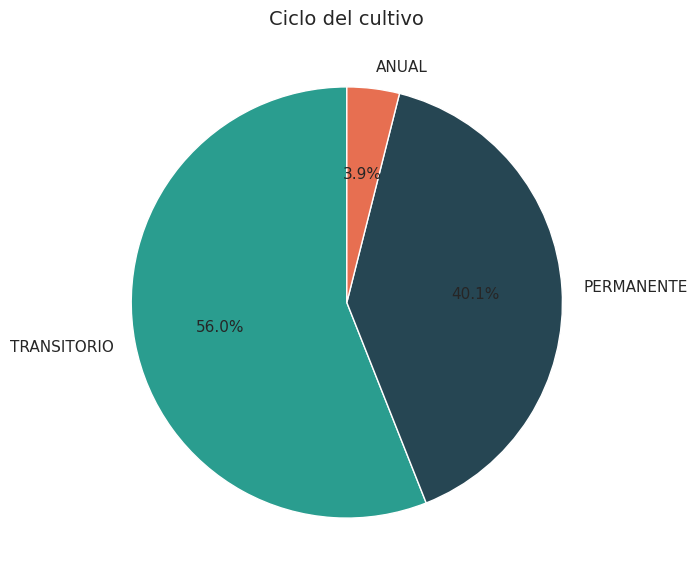

Frecuencia y porcentaje:
   TRANSITORIO : 206351 registros ( 56.0 %)
   PERMANENTE : 147644 registros ( 40.1 %)
   ANUAL : 14480 registros ( 3.9 %)


In [ ]:
# Ciclo del cultivo
conteo = datos["ciclo"].value_counts()
porcentaje = datos["ciclo"].value_counts(normalize=True) * 100

plt.figure(figsize=(7, 7))
plt.pie(conteo.values, labels=conteo.index, autopct="%1.1f%%",
        colors=[VERDE, AZUL, NARANJA], startangle=90)
plt.title("Ciclo del cultivo")
plt.show()

print("Frecuencia y porcentaje:")
for nombre in conteo.index:
    print("  ", nombre, ":", conteo[nombre], "registros (", round(porcentaje[nombre], 1), "%)")

La mayoría de los registros corresponde a cultivos **transitorios**, con **206.351 registros (56%)**, seguidos de los **permanentes** con **147.644 (40.1%)**. Los cultivos de ciclo **anual** son minoría, con apenas **14.480 registros (3.9%)**.

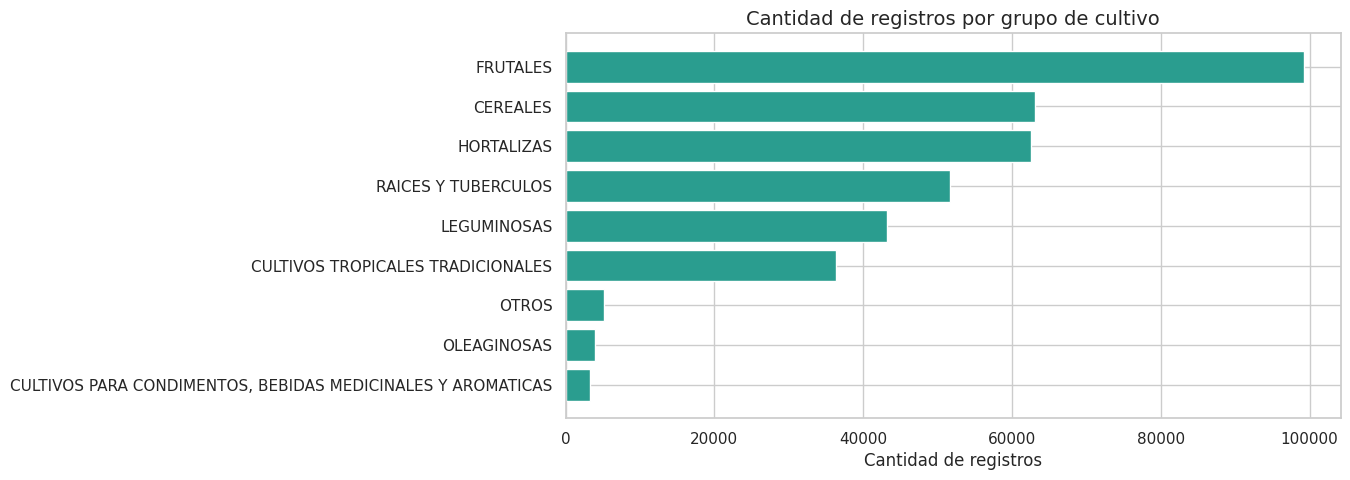

Frecuencia y porcentaje:
   FRUTALES : 99210 registros ( 26.9 %)
   CEREALES : 63065 registros ( 17.1 %)
   HORTALIZAS : 62623 registros ( 17.0 %)
   RAICES Y TUBERCULOS : 51627 registros ( 14.0 %)
   LEGUMINOSAS : 43245 registros ( 11.7 %)
   CULTIVOS TROPICALES TRADICIONALES : 36324 registros ( 9.9 %)
   OTROS : 5138 registros ( 1.4 %)
   OLEAGINOSAS : 3978 registros ( 1.1 %)
   CULTIVOS PARA CONDIMENTOS, BEBIDAS MEDICINALES Y AROMATICAS : 3265 registros ( 0.9 %)


In [ ]:
# Grupo de cultivo
conteo = datos["grupo"].value_counts()
porcentaje = datos["grupo"].value_counts(normalize=True) * 100

plt.figure(figsize=(10, 5))
plt.barh(conteo.index, conteo.values, color=VERDE)
plt.gca().invert_yaxis()
plt.title("Cantidad de registros por grupo de cultivo")
plt.xlabel("Cantidad de registros")
plt.show()

print("Frecuencia y porcentaje:")
for nombre in conteo.index:
    print("  ", nombre, ":", conteo[nombre], "registros (", round(porcentaje[nombre], 1), "%)")

El grupo con más registros es **Frutales**, con **99.210 registros (26.9%)**, seguido de **Cereales** (63.065, 17.1%) y **Hortalizas** (62.623, 17.0%). En el otro extremo, grupos como Oleaginosas y Cultivos para condimentos, bebidas medicinales y aromáticas representan menos del **1.5%** cada uno.

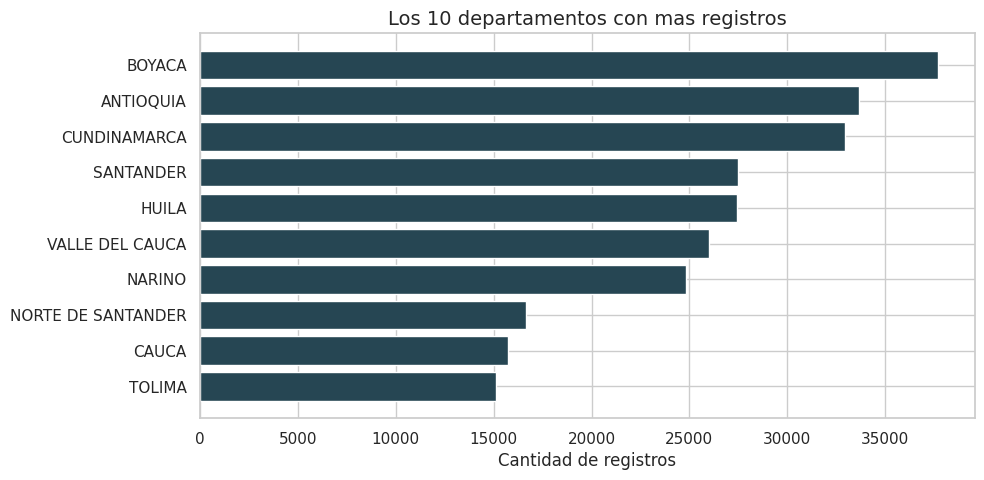

Total de departamentos: 32

   BOYACA : 37699 registros ( 10.2 %)
   ANTIOQUIA : 33637 registros ( 9.1 %)
   CUNDINAMARCA : 32954 registros ( 8.9 %)
   SANTANDER : 27488 registros ( 7.5 %)
   HUILA : 27409 registros ( 7.4 %)
   VALLE DEL CAUCA : 25982 registros ( 7.1 %)
   NARINO : 24812 registros ( 6.7 %)
   NORTE DE SANTANDER : 16669 registros ( 4.5 %)
   CAUCA : 15734 registros ( 4.3 %)
   TOLIMA : 15108 registros ( 4.1 %)


In [ ]:
# Departamentos con mas registros (son 32 en total, mostramos los 10 primeros)
conteo = datos["departamento"].value_counts().head(10)
porcentaje = datos["departamento"].value_counts(normalize=True).head(10) * 100

plt.figure(figsize=(10, 5))
plt.barh(conteo.index, conteo.values, color=AZUL)
plt.gca().invert_yaxis()
plt.title("Los 10 departamentos con mas registros")
plt.xlabel("Cantidad de registros")
plt.show()

print("Total de departamentos:", datos["departamento"].nunique())
print()
for nombre in conteo.index:
    print("  ", nombre, ":", conteo[nombre], "registros (", round(porcentaje[nombre], 1), "%)")

De los **32 departamentos**, **Boyacá** concentra la mayor cantidad de registros con **37.699 (10.2%)**, seguido de **Antioquia** (33.637, 9.1%) y **Cundinamarca** (32.954, 8.9%). Los 10 departamentos con más registros ya acumulan cerca del **70%** del total; los 22 restantes se reparten el otro 30%.

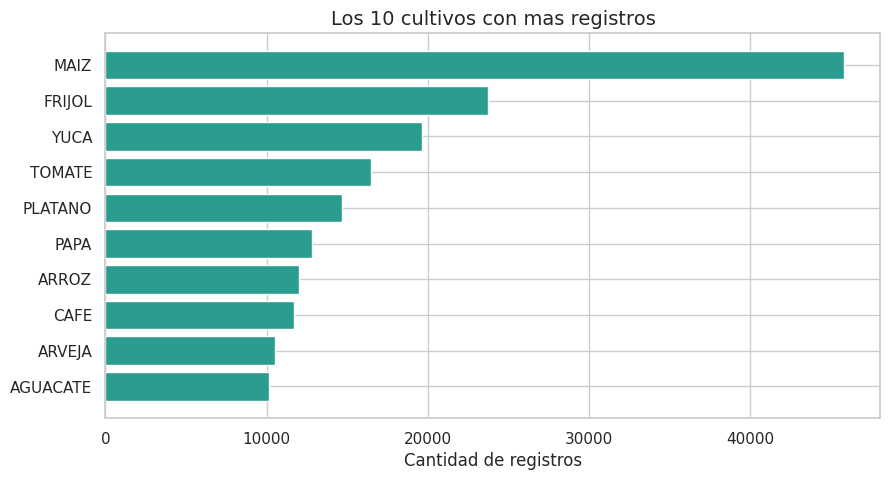

Total de cultivos diferentes: 248
Total de municipios diferentes: 1059

   MAIZ : 45796 registros ( 12.4 %)
   FRIJOL : 23753 registros ( 6.4 %)
   YUCA : 19612 registros ( 5.3 %)
   TOMATE : 16475 registros ( 4.5 %)
   PLATANO : 14700 registros ( 4.0 %)
   PAPA : 12785 registros ( 3.5 %)
   ARROZ : 11989 registros ( 3.3 %)
   CAFE : 11722 registros ( 3.2 %)
   ARVEJA : 10528 registros ( 2.9 %)
   AGUACATE : 10157 registros ( 2.8 %)


In [ ]:
# Cultivos con mas registros (hay mas de 200, mostramos los 10 primeros)
conteo = datos["cultivo"].value_counts().head(10)
porcentaje = datos["cultivo"].value_counts(normalize=True).head(10) * 100

plt.figure(figsize=(10, 5))
plt.barh(conteo.index, conteo.values, color=VERDE)
plt.gca().invert_yaxis()
plt.title("Los 10 cultivos con mas registros")
plt.xlabel("Cantidad de registros")
plt.show()

print("Total de cultivos diferentes:", datos["cultivo"].nunique())
print("Total de municipios diferentes:", datos["municipio"].nunique())
print()
for nombre in conteo.index:
    print("  ", nombre, ":", conteo[nombre], "registros (", round(porcentaje[nombre], 1), "%)")

De los **248 cultivos** distintos reportados en **1.059 municipios**, el **maíz** es el que más se registra, con **45.796 registros (12.4%)**, seguido de **fríjol** (23.753, 6.4%) y **yuca** (19.612, 5.3%). La actividad agrícola está concentrada en pocos cultivos frente al total disponible.

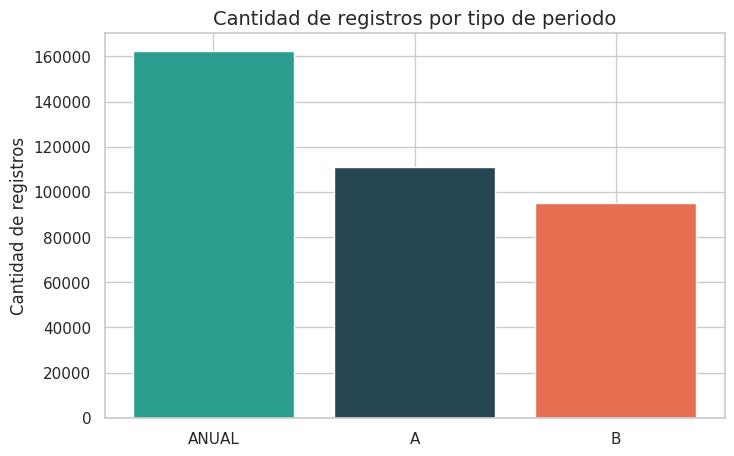

   ANUAL : 162354 registros ( 44.1 %)
   A : 110977 registros ( 30.1 %)
   B : 95144 registros ( 25.8 %)

Los reportes ANUALES son casi siempre de cultivos permanentes (cafe, cacao, platano),
que se cosechan durante todo el anio y no por semestres.


In [ ]:
# Tipo de periodo: semestre A, semestre B o reporte anual
conteo = datos["semestre"].value_counts()
porcentaje = datos["semestre"].value_counts(normalize=True) * 100

plt.figure(figsize=(8, 5))
plt.bar(conteo.index, conteo.values, color=[VERDE, AZUL, NARANJA])
plt.title("Cantidad de registros por tipo de periodo")
plt.ylabel("Cantidad de registros")
plt.show()

for nombre in conteo.index:
    print("  ", nombre, ":", conteo[nombre], "registros (", round(porcentaje[nombre], 1), "%)")
print()
print("Los reportes ANUALES son casi siempre de cultivos permanentes (cafe, cacao, platano),")
print("que se cosechan durante todo el anio y no por semestres.")

Un **44.1%** de los registros son reportes **anuales** (162.354), mientras que los semestres **A** y **B** representan **30.1%** (110.977) y **25.8%** (95.144) respectivamente. Los reportes anuales corresponden mayormente a cultivos permanentes, que no se cosechan por semestre sino durante todo el año.

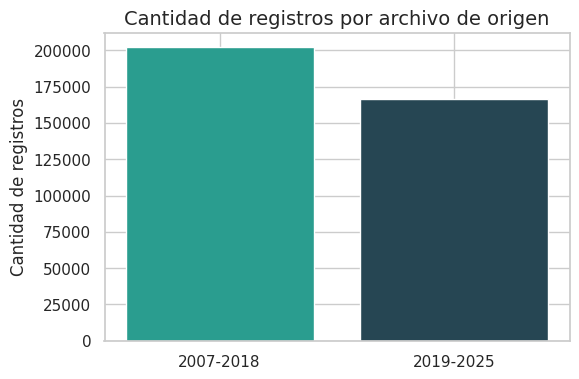

   2007-2018 : 201979 registros ( 54.8 %)
   2019-2025 : 166496 registros ( 45.2 %)


In [ ]:
# Fuente del archivo (solo 2 categorias)
conteo = datos["fuente"].value_counts()
porcentaje = datos["fuente"].value_counts(normalize=True) * 100

plt.figure(figsize=(6, 4))
plt.bar(conteo.index, conteo.values, color=[VERDE, AZUL])
plt.title("Cantidad de registros por archivo de origen")
plt.ylabel("Cantidad de registros")
plt.show()

for nombre in conteo.index:
    print("  ", nombre, ":", conteo[nombre], "registros (", round(porcentaje[nombre], 1), "%)")

El archivo viejo (2007-2018) aporta un poco más de la mitad de los registros: **201.979 (54.8%)**, frente a **166.496 (45.2%)** del archivo nuevo (2019-2025). Sin embargo el archivo nuevo cubre menos años (7 vs 12) y aun así tiene casi el mismo total — reporta a un ritmo mucho mayor (~23.800 registros/año vs ~16.800/año del archivo viejo), probablemente por mayor detalle geográfico.

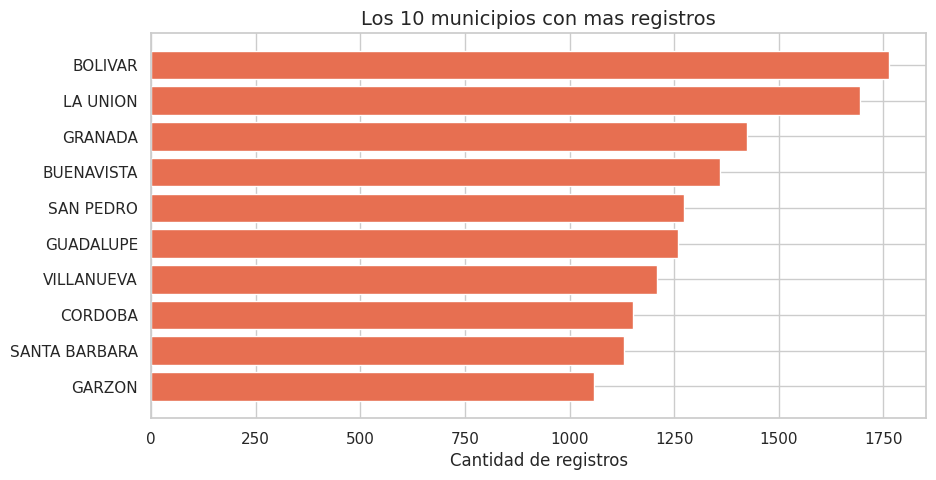

Total de municipios diferentes: 1059

   BOLIVAR : 1764 registros ( 0.48 %)
   LA UNION : 1695 registros ( 0.46 %)
   GRANADA : 1424 registros ( 0.39 %)
   BUENAVISTA : 1360 registros ( 0.37 %)
   SAN PEDRO : 1273 registros ( 0.35 %)
   GUADALUPE : 1259 registros ( 0.34 %)
   VILLANUEVA : 1209 registros ( 0.33 %)
   CORDOBA : 1151 registros ( 0.31 %)
   SANTA BARBARA : 1130 registros ( 0.31 %)
   GARZON : 1059 registros ( 0.29 %)


In [ ]:
# Municipio: hay 1059, mismo criterio que usamos con cultivo (top 10)
conteo = datos["municipio"].value_counts().head(10)
porcentaje = datos["municipio"].value_counts(normalize=True).head(10) * 100

plt.figure(figsize=(10, 5))
plt.barh(conteo.index, conteo.values, color=NARANJA)
plt.gca().invert_yaxis()
plt.title("Los 10 municipios con mas registros")
plt.xlabel("Cantidad de registros")
plt.show()

print("Total de municipios diferentes:", datos["municipio"].nunique())
print()
for nombre in conteo.index:
    print("  ", nombre, ":", conteo[nombre], "registros (", round(porcentaje[nombre], 2), "%)")

Hay **1.059 municipios** distintos, y a diferencia de `departamento` o `cultivo`, aquí ninguno domina: el municipio con más registros (**Bolívar**) apenas representa el **0.48%** del total, y entre los 10 municipios más frecuentes suman menos del **4%** combinados. Esto confirma que `municipio` está demasiado fragmentado para usarse solo como predictor — `departamento` es el nivel de agregación que sí tiene sentido.

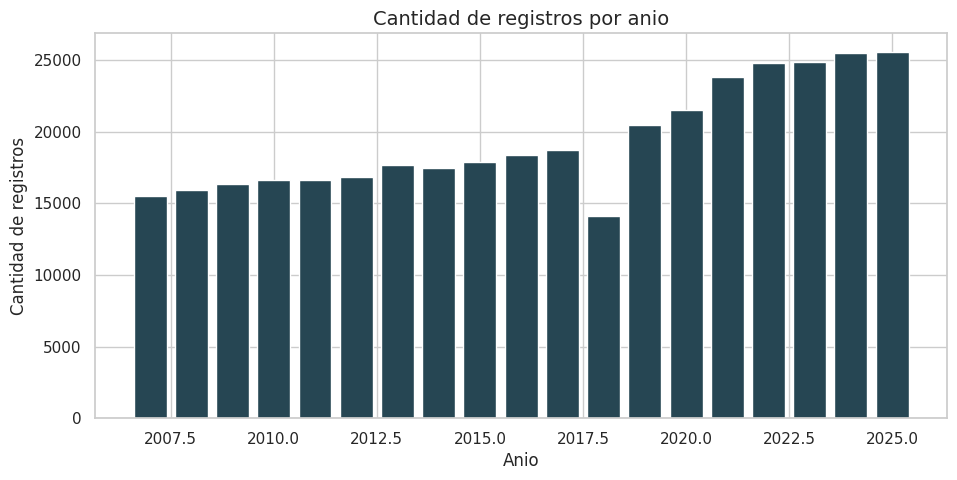

Rango: 2007 a 2025
Minimo de registros: 14090 (anio 2018 )
Maximo de registros: 25584 (anio 2025 )


In [ ]:
# Anio: es numerica pero no tiene sentido calcular asimetria/promedio de un anio,
# la mostramos como cantidad de registros por anio (igual que hicimos con semestre)
conteo = datos["anio"].value_counts().sort_index()

plt.figure(figsize=(11, 5))
plt.bar(conteo.index.astype(int), conteo.values, color=AZUL)
plt.title("Cantidad de registros por anio")
plt.xlabel("Anio")
plt.ylabel("Cantidad de registros")
plt.show()

print("Rango:", int(datos['anio'].min()), "a", int(datos['anio'].max()))
print("Minimo de registros:", conteo.min(), "(anio", conteo.idxmin(), ")")
print("Maximo de registros:", conteo.max(), "(anio", conteo.idxmax(), ")")

`anio` va de **2007 a 2025**. La cantidad de registros por año crece de forma sostenida: de **15.483 en 2007** a **25.584 en 2025** (casi se duplica), coincidiendo con lo que vimos en `fuente` — el país empieza a reportar con más detalle geográfico en años recientes. La excepción es **2018**, con solo **14.090 registros** — el año con menos reportes de toda la serie, justo el último año del archivo viejo, probablemente quedó incompleto en la fuente original.

## 4.2 Variables numericas

Para cada variable numerica graficamos el histograma y el boxplot, y reportamos la estadistica
que corresponda segun la forma que tenga.

In [ ]:
# Funcion sencilla para describir una variable numerica
def describir_numerica(columna, nombre, unidad):
    valores = columna.dropna()
    asimetria = valores.skew()

    figura, ejes = plt.subplots(1, 2, figsize=(13, 4))

    limite = valores.quantile(0.95)
    ejes[0].hist(valores[valores <= limite], bins=50, color=VERDE, edgecolor="white")
    ejes[0].set_title("Histograma de " + nombre)
    ejes[0].set_xlabel(unidad)
    ejes[0].set_ylabel("Cantidad de registros")

    if abs(asimetria) >= 1:
        # Variable muy sesgada: calculamos el boxplot SOBRE el logaritmo, no solo
        # cambiamos la escala del eje. Asi los outliers se calculan bien y no
        # sale la mancha negra.
        valores_log = np.log1p(valores)
        sns.boxplot(x=valores_log, ax=ejes[1], color=VERDE)
        ejes[1].set_title("Boxplot de " + nombre + " (escala log)")
        ejes[1].set_xlabel("log(1 + " + unidad + ")")
    else:
        sns.boxplot(x=valores, ax=ejes[1], color=VERDE)
        ejes[1].set_title("Boxplot de " + nombre)
        ejes[1].set_xlabel(unidad)

    plt.tight_layout()
    plt.show()

    print("Asimetria:", round(asimetria, 2))
    if abs(asimetria) < 0.5:
        print("La distribucion es SIMETRICA, entonces reportamos promedio y desviacion estandar:")
        print("  ", nombre, "=", round(valores.mean(), 2), "+/-", round(valores.std(), 2), unidad)
    else:
        print("La distribucion es ASIMETRICA, entonces reportamos mediana y rango intercuartil:")
        print("  mediana =", round(valores.median(), 2), unidad)
        print("  rango intercuartil =", round(valores.quantile(0.25), 2), "a",
              round(valores.quantile(0.75), 2), unidad)
        print("  rango total =", round(valores.min(), 2), "a", round(valores.max(), 2), unidad)

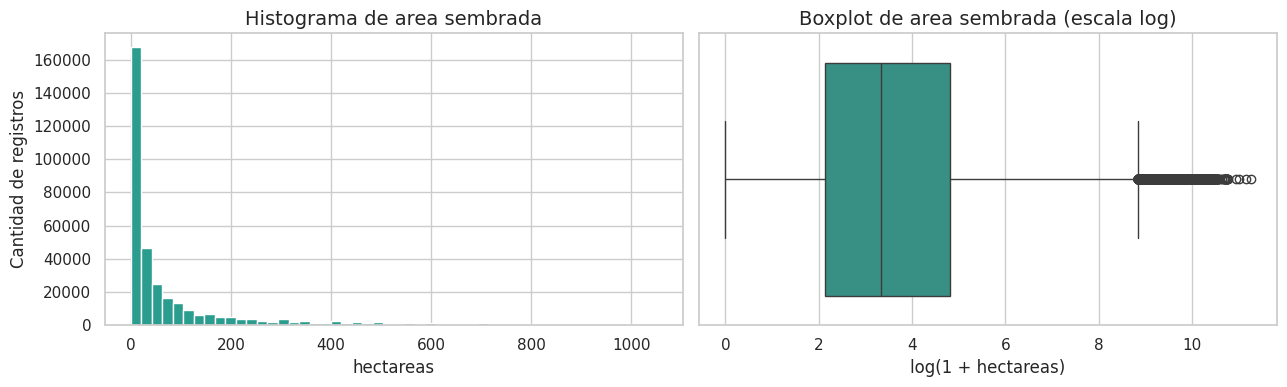

Asimetria: 16.54
La distribucion es ASIMETRICA, entonces reportamos mediana y rango intercuartil:
  mediana = 27.3 hectareas
  rango intercuartil = 7.5 a 123.0 hectareas
  rango total = 0.0 a 77630.0 hectareas


In [ ]:
describir_numerica(datos["area_sembrada"], "area sembrada", "hectareas")

 El **área sembrada** es una variable numérica **asimétrica** (asimetría = 16.54): la mediana es de **27.3 hectáreas**, con un rango intercuartil de **7.5 a 123 hectáreas**. El máximo llega a **77.630 hectáreas**, así que se reporta con mediana y rango intercuartil, no con promedio.

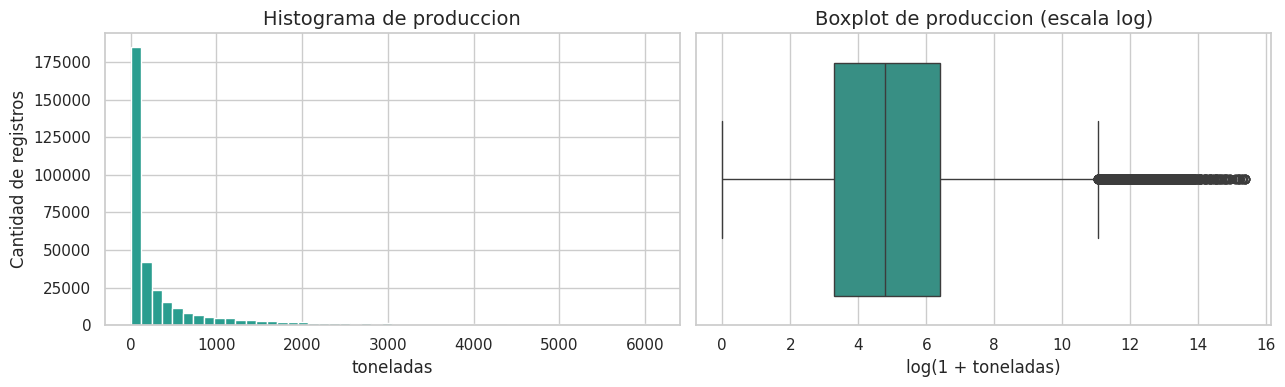

Asimetria: 56.01
La distribucion es ASIMETRICA, entonces reportamos mediana y rango intercuartil:
  mediana = 120.0 toneladas
  rango intercuartil = 26.0 a 600.0 toneladas
  rango total = 0.0 a 4776340.5 toneladas


In [ ]:
describir_numerica(datos["produccion"], "produccion", "toneladas")

La **producción** también es fuertemente asimétrica (asimetría = 56.01): la mediana es de **120 toneladas**, con un rango intercuartil de **26 a 600 toneladas**. El valor máximo (**4.776.340 toneladas**) es un caso extremo que confirma que el promedio no representa bien esta variable.

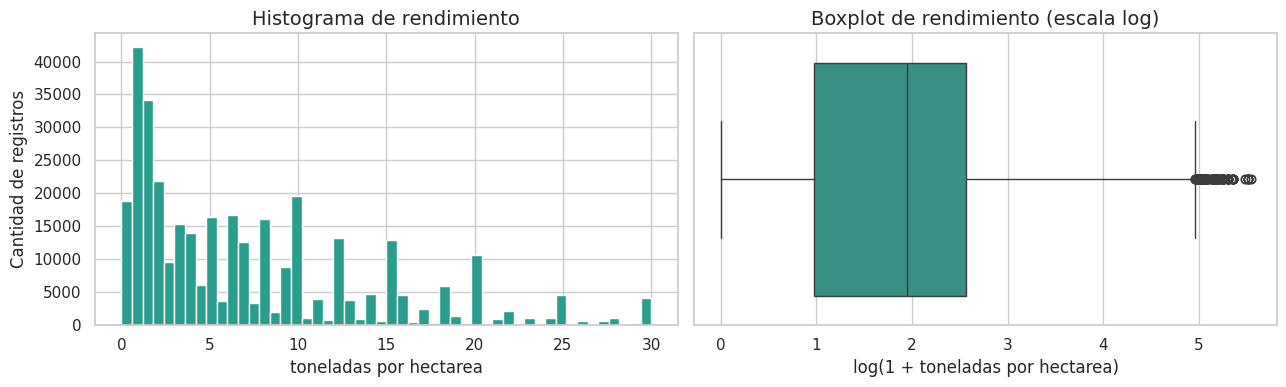

Asimetria: 4.78
La distribucion es ASIMETRICA, entonces reportamos mediana y rango intercuartil:
  mediana = 6.0 toneladas por hectarea
  rango intercuartil = 1.64 a 12.0 toneladas por hectarea
  rango total = 0.0 a 253.0 toneladas por hectarea


In [ ]:
describir_numerica(datos["rendimiento"], "rendimiento", "toneladas por hectarea")

El **rendimiento** (t/ha) tiene una asimetría de **4.78**: la mediana es de **6 t/ha**, con rango intercuartil de **1.64 a 12 t/ha**. Aunque menos extrema que las otras dos variables, sigue siendo asimétrica, así que se reporta igual con mediana y rango intercuartil.

In [ ]:
# Tabla resumen de todas las variables numericas (para pasarla a las diapositivas)
resumen = datos[["area_sembrada", "area_cosechada", "produccion", "rendimiento"]].describe().T
resumen["asimetria"] = datos[["area_sembrada", "area_cosechada",
                              "produccion", "rendimiento"]].skew()
resumen = resumen.round(2)
resumen

,count,mean,std,min,25%,50%,75%,max,asimetria
area_sembrada,"368,475.00",263.92,"1,176.79",0.00,7.50,27.30,123.00,"77,630.00",16.54
area_cosechada,"368,475.00",231.93,"1,049.94",0.00,6.00,22.50,103.94,"77,630.00",16.94
produccion,"368,475.00","2,992.51","47,280.59",0.00,26.00,120.00,600.00,"4,776,340.50",56.01
rendimiento,"365,045.00",9.88,15.24,0.00,1.64,6.00,12.00,253.00,4.78


---
# 5. Variable objetivo: Area cosechada

**Que es:** el area cosechada son las hectareas que realmente se recogieron de un cultivo en un
municipio durante un periodo.

**En que se diferencia del area sembrada:** el area sembrada es lo que se planto. La diferencia
entre las dos es lo que se perdio por clima, plagas o problemas en la cosecha. Por eso el area
cosechada es la que muestra la produccion real del pais.

**Que queremos predecir en las fases 2 y 3:** dado un municipio, un cultivo y un periodo,
estimar cuantas hectareas se van a cosechar. Como es un numero, es un problema de regresion.

Esta seccion tiene 4 partes:

| Parte | Contenido |
|---|---|
| 5.1 | Reglas de limpieza para la variable objetivo |
| 5.2 | Analisis estadistico (graficos y numeros) |
| 5.3 | Correlaciones y situaciones interesantes |
| 5.4 | Desafios de la variable |

## 5.1 Reglas de limpieza para la variable objetivo

Antes de describir la variable, hay que revisar si tiene valores imposibles. Usamos tres reglas
que siempre se deben cumplir en un cultivo:

1. No se puede cosechar mas de lo que se sembro.
2. No puede haber produccion si no se cosecho nada.
3. El area cosechada en cero significa que se perdio toda la cosecha, o que no reportaron.

In [ ]:
# Contamos cuantas filas rompen cada regla
regla_1 = datos["area_cosechada"] > datos["area_sembrada"]
regla_2 = (datos["produccion"] > 0) & (datos["area_cosechada"] == 0)
regla_3 = datos["area_cosechada"] == 0

print("PROBLEMAS ENCONTRADOS (sobre", len(datos), "filas)")
print()
print("1. Cosecharon mas de lo que sembraron :", regla_1.sum(), "filas",
      "(", round(regla_1.mean() * 100, 2), "%)")
print("2. Hay produccion pero area cosechada 0:", regla_2.sum(), "filas",
      "(", round(regla_2.mean() * 100, 2), "%)")
print("3. Area cosechada igual a cero        :", regla_3.sum(), "filas",
      "(", round(regla_3.mean() * 100, 2), "%)")

PROBLEMAS ENCONTRADOS (sobre 368475 filas)

1. Cosecharon mas de lo que sembraron : 13253 filas ( 3.6 %)
2. Hay produccion pero area cosechada 0: 717 filas ( 0.19 %)
3. Area cosechada igual a cero        : 11433 filas ( 3.1 %)


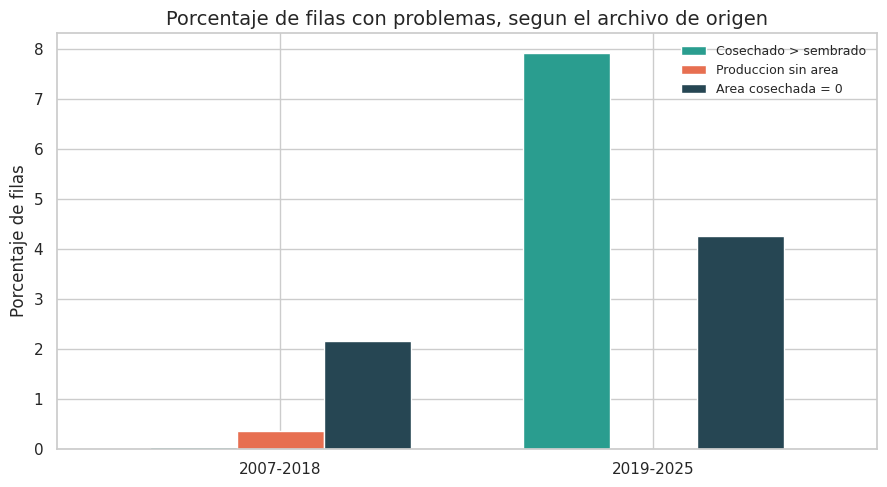

           problema_1  problema_2  problema_3
fuente                                       
2007-2018        0.03        0.35        2.15
2019-2025        7.92        0.00        4.26


In [ ]:
# Guardamos las reglas como columnas, para poder comparar entre archivos
datos["problema_1"] = regla_1
datos["problema_2"] = regla_2
datos["problema_3"] = regla_3

comparacion = datos.groupby("fuente")[["problema_1", "problema_2", "problema_3"]].mean() * 100
comparacion = comparacion.round(2)

plt.figure(figsize=(9, 5))
comparacion.plot(kind="bar", color=[VERDE, NARANJA, AZUL], ax=plt.gca(), width=0.7)
plt.title("Porcentaje de filas con problemas, segun el archivo de origen")
plt.ylabel("Porcentaje de filas")
plt.xlabel("")
plt.xticks(rotation=0)
plt.legend(["Cosechado > sembrado", "Produccion sin area", "Area cosechada = 0"],
           frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

print(comparacion)

**Hallazgo importante:** los problemas no estan repartidos igual entre los dos archivos.

En el archivo nuevo (2019-2025) hay muchas mas filas donde el area cosechada es mayor que la
sembrada. Esto pasa sobre todo en cultivos transitorios y probablemente se debe a que cambiaron
la forma de diligenciar el formulario: reportan el area sembrada del semestre, pero el area
cosechada incluye siembras del semestre anterior.

Por eso la columna `fuente` es importante y hay que tenerla en cuenta en la Fase 2.

In [ ]:
# Antes de borrar nada, revisamos los valores mas grandes: ¿son errores o son reales?
mas_grandes = datos.nlargest(10, "area_cosechada")
mas_grandes[["anio", "departamento", "municipio", "cultivo",
             "area_sembrada", "area_cosechada", "produccion"]]

,anio,departamento,municipio,cultivo,area_sembrada,area_cosechada,produccion
308219,2025,META,PUERTO GAITAN,SOYA,"1,500.00","77,630.00","194,075.00"
308215,2023,META,PUERTO GAITAN,SOYA,"1,000.00","61,000.00","137,250.00"
308217,2024,META,PUERTO GAITAN,SOYA,"1,200.00","57,000.00","128,250.00"
342271,2022,SANTANDER,PUERTO WILCHES,PALMA DE ACEITE,"46,307.00","46,264.00","222,067.20"
342272,2023,SANTANDER,PUERTO WILCHES,PALMA DE ACEITE,"46,312.00","46,212.00","221,817.60"
342273,2024,SANTANDER,PUERTO WILCHES,PALMA DE ACEITE,"46,312.00","46,212.00","221,817.60"
342274,2025,SANTANDER,PUERTO WILCHES,PALMA DE ACEITE,"46,312.00","46,212.00","224,128.20"
342270,2021,SANTANDER,PUERTO WILCHES,PALMA DE ACEITE,"46,350.00","45,000.00","216,000.00"
342269,2020,SANTANDER,PUERTO WILCHES,PALMA DE ACEITE,"45,000.00","38,702.00","185,769.60"
144945,2011,META,SAN CARLOS DE GUAROA,PALMA DE ACEITE,"43,600.00","38,600.00","115,800.00"


Al mirar la tabla se ven dos casos muy distintos:

- **La soya de Puerto Gaitan (Meta)** aparece con 1.500 hectareas sembradas y 77.630 cosechadas.
  Eso es imposible: se cosecho 50 veces mas de lo que se sembro. **Es un error de digitacion**
  y lo vamos a eliminar con la regla 1.
- **La palma de Puerto Wilches (Santander)** aparece con 46.312 sembradas y 46.264 cosechadas.
  Eso si tiene sentido: es un municipio palmero enorme. **Es un dato real** aunque el boxplot
  lo marque como valor atipico, y por eso lo conservamos.

Esto muestra por que no se pueden borrar los valores atipicos solo por ser grandes: hay que
revisarlos uno por uno. Si borraramos todos los valores altos, perderiamos justamente los
municipios que mas producen en el pais.

**Que decidimos hacer con cada problema:**

| Problema | Decision | Por que |
|---|---|---|
| Cosechado mayor que sembrado | **Borrar esas filas** | Es fisicamente imposible, el dato esta mal |
| Produccion sin area cosechada | **Borrar esas filas** | Tambien es imposible |
| Area cosechada igual a cero | **Dejarlas por ahora** | Puede ser una perdida real de la cosecha; lo decidimos en la Fase 2 |
| Valores muy grandes (outliers) | **Dejarlos** | Son municipios grandes de verdad, no errores (ya lo revisamos arriba) |

In [ ]:
# Creamos la tabla limpia quitando solo las filas imposibles
datos_limpios = datos[(datos["area_cosechada"] <= datos["area_sembrada"]) &
                      ~((datos["produccion"] > 0) & (datos["area_cosechada"] == 0))]

datos_limpios = datos_limpios.copy()

print("Filas antes de limpiar :", len(datos))
print("Filas despues de limpiar:", len(datos_limpios))
print("Filas eliminadas        :", len(datos) - len(datos_limpios),
      "(", round((len(datos) - len(datos_limpios)) / len(datos) * 100, 2), "% del total )")

Filas antes de limpiar : 368475
Filas despues de limpiar: 354505
Filas eliminadas        : 13970 ( 3.79 % del total )


In [ ]:
# Volvemos a mirar los valores mas grandes: ahora todos tienen sentido
datos_limpios.nlargest(10, "area_cosechada")[["anio", "departamento", "municipio", "cultivo",
                                              "area_sembrada", "area_cosechada", "produccion"]]

,anio,departamento,municipio,cultivo,area_sembrada,area_cosechada,produccion
342271,2022,SANTANDER,PUERTO WILCHES,PALMA DE ACEITE,"46,307.00","46,264.00","222,067.20"
342272,2023,SANTANDER,PUERTO WILCHES,PALMA DE ACEITE,"46,312.00","46,212.00","221,817.60"
342273,2024,SANTANDER,PUERTO WILCHES,PALMA DE ACEITE,"46,312.00","46,212.00","221,817.60"
342274,2025,SANTANDER,PUERTO WILCHES,PALMA DE ACEITE,"46,312.00","46,212.00","224,128.20"
342270,2021,SANTANDER,PUERTO WILCHES,PALMA DE ACEITE,"46,350.00","45,000.00","216,000.00"
342269,2020,SANTANDER,PUERTO WILCHES,PALMA DE ACEITE,"45,000.00","38,702.00","185,769.60"
144945,2011,META,SAN CARLOS DE GUAROA,PALMA DE ACEITE,"43,600.00","38,600.00","115,800.00"
368326,2021,CASANARE,PAZ DE ARIPORO,ARROZ,"37,418.00","37,418.00","202,057.20"
342268,2019,SANTANDER,PUERTO WILCHES,PALMA DE ACEITE,"38,702.00","37,000.00","177,600.00"
368324,2020,CASANARE,PAZ DE ARIPORO,ARROZ,"35,958.00","35,958.00","194,448.00"


El error de la soya de Puerto Gaitan ya no aparece: el valor mas alto ahora es la palma de
Puerto Wilches, un dato real.

**De aqui en adelante, todos los graficos y estadisticas de esta seccion usan `datos_limpios`**
(la tabla despues de quitar las filas imposibles), para que el analisis sea congruente con la
limpieza que acabamos de hacer.

## 5.2 Analisis estadistico de la variable objetivo

Seguimos la misma regla del parcial que usamos con las demas variables: primero graficamos, y
segun lo que se vea, elegimos que estadistica reportar.

In [ ]:
# Tabla resumen de la variable objetivo (ya sobre los datos limpios)
oc = datos_limpios["area_cosechada"]

resumen_objetivo = pd.DataFrame({
    "Estadistica": ["Cantidad de datos", "Valores faltantes", "Valores en cero",
                     "Porcentaje en cero (%)", "Minimo (ha)", "Cuartil 1 (ha)",
                     "Mediana (ha)", "Cuartil 3 (ha)", "Maximo (ha)",
                     "Promedio (ha)", "Desviacion estandar (ha)", "Asimetria"],
    "Valor": [len(oc), oc.isna().sum(), (oc == 0).sum(), (oc == 0).mean() * 100,
              oc.min(), oc.quantile(0.25), oc.median(), oc.quantile(0.75), oc.max(),
              oc.mean(), oc.std(), oc.skew()]
})
resumen_objetivo["Valor"] = resumen_objetivo["Valor"].round(2)
resumen_objetivo

,Estadistica,Valor
0,Cantidad de datos,"354,505.00"
1,Valores faltantes,0.00
2,Valores en cero,"10,716.00"
3,Porcentaje en cero (%),3.02
4,Minimo (ha),0.00
5,Cuartil 1 (ha),6.00
6,Mediana (ha),22.00
7,Cuartil 3 (ha),101.00
8,Maximo (ha),"46,264.00"
9,Promedio (ha),229.58


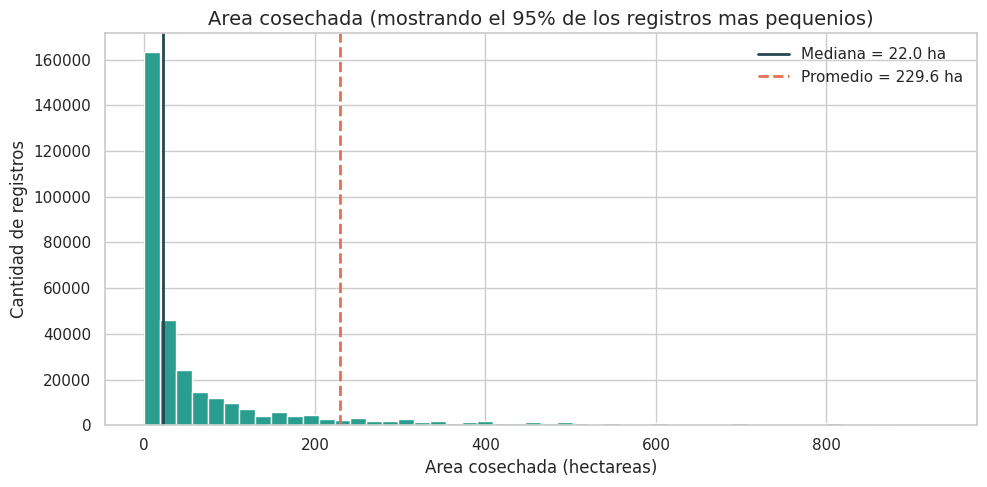

El promedio es mucho mas grande que la mediana.
Eso pasa porque los municipios muy grandes jalan el promedio hacia arriba.
El otro 5% de los registros (los mas grandes) llega hasta 46264.0 hectareas.


In [ ]:
# Primero graficamos, y despues decidimos que estadistica reportar.
# Recortamos al percentil 95 para poder ver bien la forma (el resto son valores muy grandes).
limite = oc.quantile(0.95)

plt.figure(figsize=(10, 5))
plt.hist(oc[oc <= limite], bins=50, color=VERDE, edgecolor="white")
plt.axvline(oc.median(), color=AZUL, linewidth=2,
            label="Mediana = " + str(round(oc.median(), 1)) + " ha")
plt.axvline(oc.mean(), color=NARANJA, linewidth=2, linestyle="--",
            label="Promedio = " + str(round(oc.mean(), 1)) + " ha")
plt.title("Area cosechada (mostrando el 95% de los registros mas pequenios)")
plt.xlabel("Area cosechada (hectareas)")
plt.ylabel("Cantidad de registros")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

print("El promedio es mucho mas grande que la mediana.")
print("Eso pasa porque los municipios muy grandes jalan el promedio hacia arriba.")
print("El otro 5% de los registros (los mas grandes) llega hasta", round(oc.max(), 0), "hectareas.")

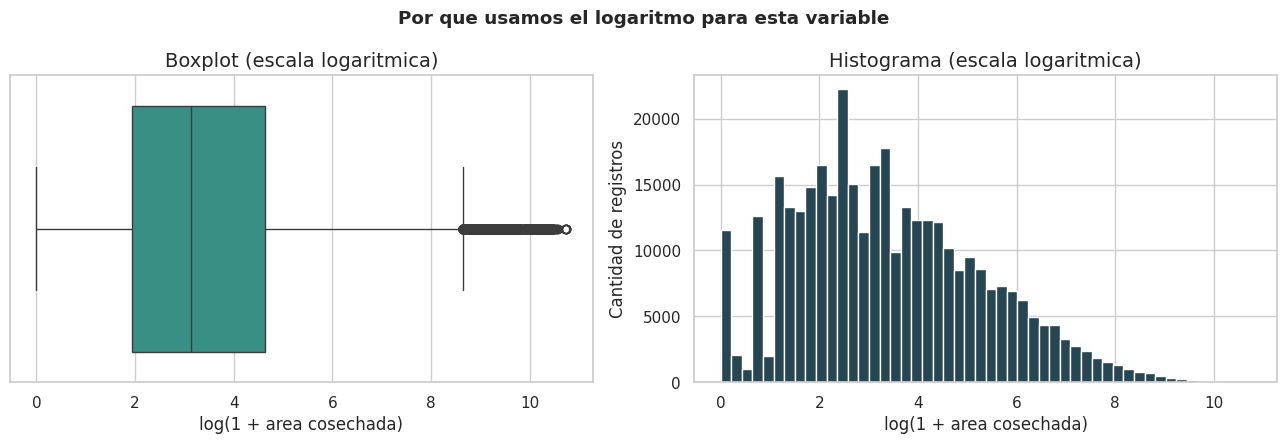

En escala normal el boxplot queda aplastado contra el cero, porque unos pocos
municipios con miles de hectareas estiran el eje. Con el logaritmo se ve la caja,
la mediana y los bigotes con claridad, y el histograma toma forma de campana.
Por eso en la Fase 2 vamos a entrenar el modelo usando log(1 + area cosechada).


In [ ]:
# La variable esta muy sesgada, asi que probamos verla con el logaritmo.
# El logaritmo comprime los valores grandes y deja ver mejor la forma de la distribucion.
datos_limpios["area_log"] = np.log1p(datos_limpios["area_cosechada"])

figura, ejes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.boxplot(x=datos_limpios["area_log"], ax=ejes[0], color=VERDE)
ejes[0].set_title("Boxplot (escala logaritmica)")
ejes[0].set_xlabel("log(1 + area cosechada)")

ejes[1].hist(datos_limpios["area_log"], bins=50, color=AZUL, edgecolor="white")
ejes[1].set_title("Histograma (escala logaritmica)")
ejes[1].set_xlabel("log(1 + area cosechada)")
ejes[1].set_ylabel("Cantidad de registros")

plt.suptitle("Por que usamos el logaritmo para esta variable", fontweight="bold")
plt.tight_layout()
plt.show()

print("En escala normal el boxplot queda aplastado contra el cero, porque unos pocos")
print("municipios con miles de hectareas estiran el eje. Con el logaritmo se ve la caja,")
print("la mediana y los bigotes con claridad, y el histograma toma forma de campana.")
print("Por eso en la Fase 2 vamos a entrenar el modelo usando log(1 + area cosechada).")

### Conclusion: como reportamos esta variable

Siguiendo la regla del parcial, la variable objetivo es **numerica asimetrica**:

- El histograma esta inclinado hacia un lado y el boxplot (en escala normal) queda aplastado.
- El promedio es diez veces la mediana, asi que el promedio no representa a un municipio tipico.

Entonces la reportamos con **mediana y rango intercuartil**, no con promedio y desviacion
estandar:

> El area cosechada tiene una mediana de **22 hectareas** y un rango intercuartil de
> **6 a 101 hectareas** (el 50% de los municipios esta en ese rango). El rango total, ya sin el
> error de la soya de Puerto Gaitan, va de **0 a 46.264 hectareas**.

## 5.3 Correlaciones y situaciones interesantes

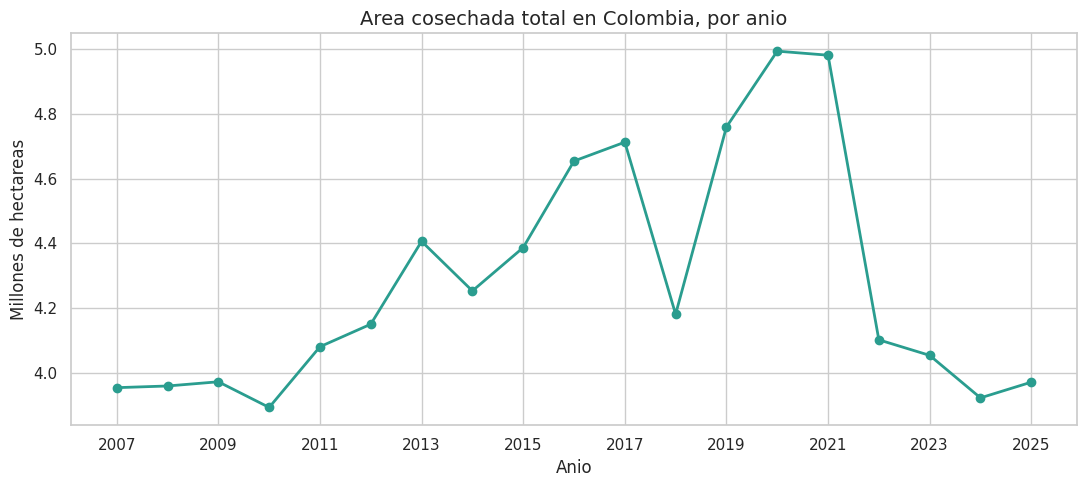

El anio 2018 tiene menos registros que los demas (14066),
por eso se ve mas bajo en la grafica: el reporte de ese anio quedo incompleto.

Tambien se ve una caida despues de 2021. No es por menos registros: 2022 tiene 21681 registros, un numero parecido a los 21501 de 2020,
pero con menos area cosechada total. Puede reflejar un cambio real en el campo,
algo que se sale del alcance de este EDA.


In [ ]:
# Como ha cambiado el area cosechada total del pais, anio por anio
area_por_anio = datos_limpios.groupby("anio")["area_cosechada"].sum()

plt.figure(figsize=(11, 5))
plt.plot(area_por_anio.index, area_por_anio.values / 1000000, marker="o",
         color=VERDE, linewidth=2)
plt.title("Area cosechada total en Colombia, por anio")
plt.xlabel("Anio")
plt.ylabel("Millones de hectareas")
plt.xticks(range(2007, 2026, 2))
plt.tight_layout()
plt.show()

registros_2018 = (datos_limpios["anio"] == 2018).sum()
registros_2020 = (datos_limpios["anio"] == 2020).sum()
registros_2022 = (datos_limpios["anio"] == 2022).sum()
print("El anio 2018 tiene menos registros que los demas (" + str(registros_2018) + "),")
print("por eso se ve mas bajo en la grafica: el reporte de ese anio quedo incompleto.")
print()
print("Tambien se ve una caida despues de 2021. No es por menos registros: 2022 tiene",
      registros_2022, "registros, un numero parecido a los", registros_2020, "de 2020,")
print("pero con menos area cosechada total. Puede reflejar un cambio real en el campo,")
print("algo que se sale del alcance de este EDA.")

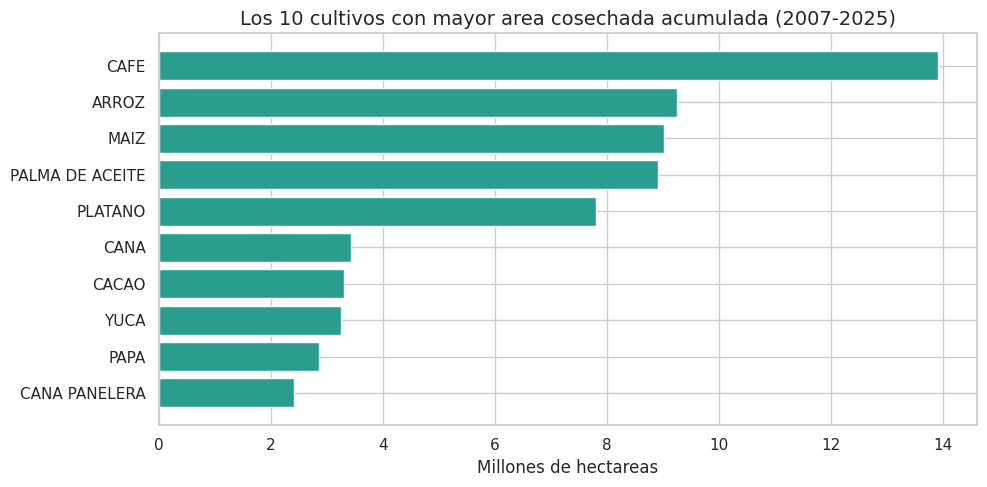

In [ ]:
# Los 10 cultivos con mas area cosechada acumulada
top_cultivos = datos_limpios.groupby("cultivo")["area_cosechada"].sum().nlargest(10)

plt.figure(figsize=(10, 5))
plt.barh(top_cultivos.index, top_cultivos.values / 1000000, color=VERDE)
plt.gca().invert_yaxis()
plt.title("Los 10 cultivos con mayor area cosechada acumulada (2007-2025)")
plt.xlabel("Millones de hectareas")
plt.tight_layout()
plt.show()

In [ ]:
# Los 10 departamentos con mas area cosechada acumulada (grafica interactiva)
top_departamentos = datos_limpios.groupby("departamento", as_index=False)["area_cosechada"].sum()
top_departamentos = top_departamentos.nlargest(10, "area_cosechada")

figura = px.bar(
    top_departamentos, x="area_cosechada", y="departamento", orientation="h",
    title="Los 10 departamentos con mayor area cosechada acumulada",
    labels={"area_cosechada": "Area cosechada (hectareas)", "departamento": ""},
    color_discrete_sequence=["#2a9d8f"]
)
figura.update_layout(yaxis={"categoryorder": "total ascending"}, height=500)
figura.show()

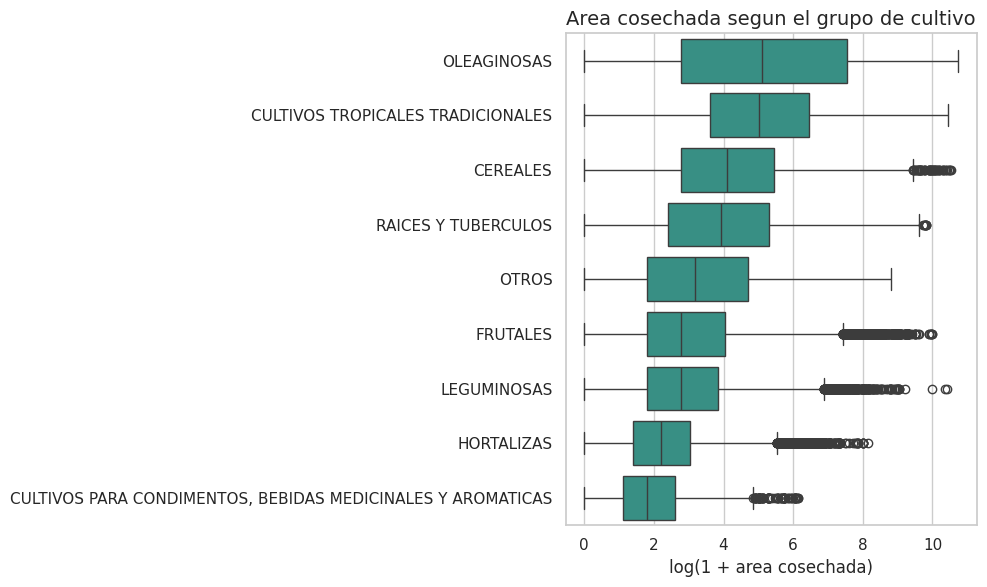

Mediana del area cosechada por grupo (hectareas):
grupo
OLEAGINOSAS                                                   165.00
CULTIVOS TROPICALES TRADICIONALES                             150.00
CEREALES                                                       59.00
RAICES Y TUBERCULOS                                            50.00
OTROS                                                          23.00
FRUTALES                                                       15.00
LEGUMINOSAS                                                    15.00
HORTALIZAS                                                      8.00
CULTIVOS PARA CONDIMENTOS, BEBIDAS MEDICINALES Y AROMATICAS     5.00
Name: area_cosechada, dtype: float64


In [ ]:
# El area cosechada segun el grupo de cultivo (usamos la escala log que ya calculamos)
orden = datos_limpios.groupby("grupo")["area_cosechada"].median().sort_values(ascending=False).index

plt.figure(figsize=(10, 6))
sns.boxplot(data=datos_limpios, y="grupo", x="area_log", order=orden, color=VERDE)
plt.title("Area cosechada segun el grupo de cultivo")
plt.xlabel("log(1 + area cosechada)")
plt.ylabel("")
plt.tight_layout()
plt.show()

print("Mediana del area cosechada por grupo (hectareas):")
print(datos_limpios.groupby("grupo")["area_cosechada"].median().sort_values(ascending=False))

In [ ]:
# Evolucion del area cosechada de los 5 cultivos principales (grafica interactiva)
top_5 = datos_limpios.groupby("cultivo")["area_cosechada"].sum().nlargest(5).index
datos_top5 = datos_limpios[datos_limpios["cultivo"].isin(top_5)]
evolucion = datos_top5.groupby(["anio", "cultivo"], as_index=False)["area_cosechada"].sum()

figura = px.line(evolucion, x="anio", y="area_cosechada", color="cultivo", markers=True,
                 title="Evolucion del area cosechada de los 5 cultivos principales",
                 labels={"anio": "Anio", "area_cosechada": "Area cosechada (hectareas)",
                         "cultivo": "Cultivo"})
figura.show()

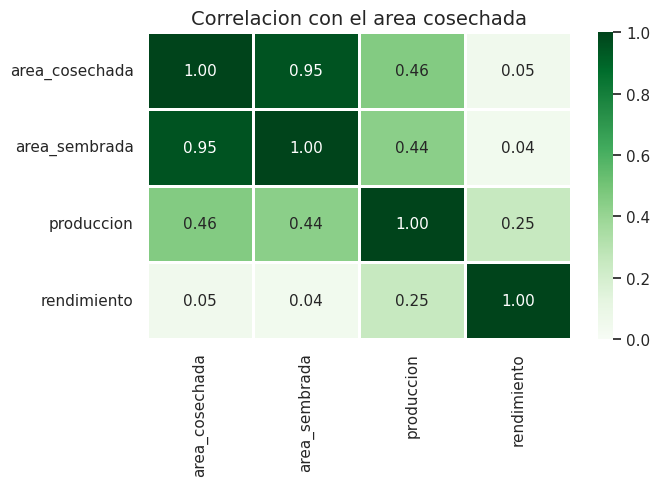

La correlacion va de 0 a 1: entre mas cerca de 1, mas relacionadas estan.

Correlacion de cada variable con el area cosechada:
area_cosechada   1.00
area_sembrada    0.95
produccion       0.46
rendimiento      0.05
Name: area_cosechada, dtype: float64


In [ ]:
# Correlacion entre las variables numericas
orden_columnas = ["area_cosechada", "area_sembrada", "produccion", "rendimiento"]
correlacion = datos_limpios[orden_columnas].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(correlacion, annot=True, cmap="Greens", vmin=0, vmax=1,
            linewidths=1, fmt=".2f")
plt.title("Correlacion con el area cosechada")
plt.tight_layout()
plt.show()

print("La correlacion va de 0 a 1: entre mas cerca de 1, mas relacionadas estan.")
print()
print("Correlacion de cada variable con el area cosechada:")
print(correlacion["area_cosechada"].sort_values(ascending=False))

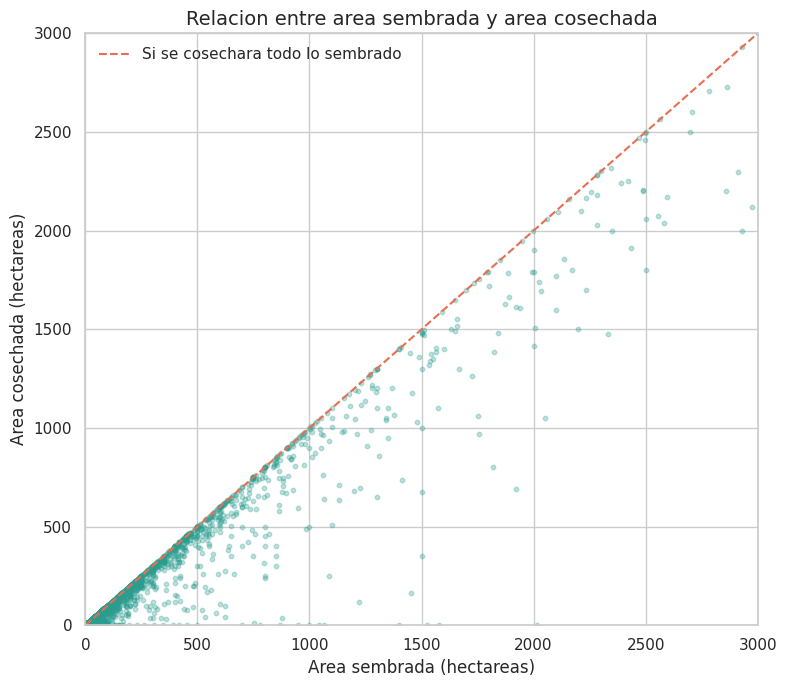

En el 48.9 % de las filas se cosecho exactamente lo mismo que se sembro.
Por eso casi todos los puntos caen sobre la linea naranja.


In [ ]:
# La relacion mas fuerte es area sembrada con area cosechada. La vemos en un grafico de dispersion.
muestra = datos_limpios.sample(5000, random_state=1)

plt.figure(figsize=(8, 7))
plt.scatter(muestra["area_sembrada"], muestra["area_cosechada"],
            s=10, alpha=0.3, color=VERDE)
plt.plot([0, 3000], [0, 3000], color=NARANJA, linestyle="--",
         label="Si se cosechara todo lo sembrado")
plt.xlim(0, 3000)
plt.ylim(0, 3000)
plt.title("Relacion entre area sembrada y area cosechada")
plt.xlabel("Area sembrada (hectareas)")
plt.ylabel("Area cosechada (hectareas)")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

iguales = (datos_limpios["area_sembrada"] == datos_limpios["area_cosechada"]).mean() * 100
print("En el", round(iguales, 1), "% de las filas se cosecho exactamente lo mismo que se sembro.")
print("Por eso casi todos los puntos caen sobre la linea naranja.")

**Hallazgos clave de esta parte:**

1. El **area sembrada** es, por lejos, la variable mas relacionada con el area cosechada
   (correlacion de 0.95). La produccion y el rendimiento aportan mucho menos por si solos
   (0.46 y 0.05).
2. En casi la mitad de las filas (48.9%) el area cosechada es exactamente igual a la sembrada.
   Esto es una senial de alerta: si el modelo de la Fase 2 solo aprende a copiar el area
   sembrada, no estaria prediciendo nada nuevo, solo repitiendo un dato que ya conocemos.
3. El **tipo de cultivo** importa mucho: las oleaginosas y los cultivos tropicales tradicionales
   (palma, cacao, cafe) ocupan areas medianas de 150-165 hectareas, mientras que las hortalizas
   apenas llegan a 8. El cultivo explica mas diferencias que el departamento.
4. El 2018 aparece con menos area cosechada total, pero es solo porque ese anio tiene menos
   registros reportados, no porque haya bajado la produccion real del pais.

## 5.4 Desafios de la variable objetivo

Ademas de los desafios generales del dataset (seccion 1.5), el analisis de esta seccion muestra
retos propios de predecir especificamente el area cosechada:

| Desafio | Por que importa para la Fase 2 |
|---|---|
| Depende de eventos posteriores a la siembra (clima, plagas, decision del productor) | No existe una formula que la calcule; por eso se necesita un modelo que aprenda del historico |
| Riesgo de fuga de informacion | `Produccion = Rendimiento x Area cosechada`, asi que no se pueden usar esas dos variables del mismo periodo como si fueran independientes |
| El area sembrada es un predictor casi perfecto en la mitad de los casos | Hay que evitar que el modelo simplemente copie el area sembrada; lo interesante es predecir bien el otro 51%, donde si hubo perdida |
| Escalas muy distintas segun el cultivo (asimetria = 15.6) | Los errores del modelo no se pueden medir igual en un cultivo de 8 ha que en uno de 165 ha; conviene evaluar por grupo y usar la escala logaritmica |
| El 3% de area cosechada en cero es ambiguo | Puede ser perdida total real o simplemente que no se reporto; hay que decidir si se incluye o se excluye del modelo |
| Cambio de protocolo entre los dos archivos | El archivo nuevo tiene muchas mas filas de "cosechada > sembrada"; el modelo debe poder manejar ese salto entre periodos |

---
# 7. Conclusiones y proximos pasos

## Lo que encontramos

**Sobre los datos**

1. Los dos archivos se pudieron unir sin problema despues de renombrar las columnas, convertir
   los numeros y arreglar los nombres de los departamentos. Quedo una tabla de mas de 370.000
   filas con 20 anios de informacion (2006 a 2025).
2. La variable objetivo no tiene datos faltantes. Aparecieron 254 filas repetidas al quedarnos
   con menos columnas y las eliminamos.

**Sobre la variable objetivo**

3. El area cosechada es una variable **muy asimetrica**: la mediana es de 23 hectareas pero el
   maximo llega a 77.630. Por eso la reportamos con mediana y rango intercuartil.
4. Usando el logaritmo la distribucion se vuelve una campana, lo que sera util para el modelo.
5. Revisamos los valores mas altos uno por uno: algunos eran errores (la soya de Puerto Gaitan)
   y otros eran reales (la palma de Puerto Wilches). Borramos los primeros y conservamos los
   segundos.

**Sobre la calidad**

6. Encontramos filas imposibles y las eliminamos, pero son pocas comparadas con el total.
7. Los problemas no estan repartidos igual entre los dos archivos: el archivo nuevo tiene
   muchas mas filas con area cosechada mayor que la sembrada. Cambio la forma de reportar.

**Sobre los patrones**

8. El **area sembrada** es la variable mas relacionada con el area cosechada.
9. En casi la mitad de las filas el area cosechada es exactamente igual a la sembrada, lo que
   indica que en muchos municipios copian el dato.
10. El tipo de cultivo influye mas que el departamento: los cereales y las oleaginosas ocupan
    areas mucho mas grandes que las hortalizas.

## Que sigue en la Fase 2

1. Decidir si trabajamos con todos los anios o solo con el archivo nuevo (2019-2025).
2. Decidir que hacer con las filas donde el area cosechada es cero.
3. Recalcular el rendimiento que falta en el archivo viejo.
4. Convertir las variables de texto (cultivo, departamento) en numeros para poder usarlas en el
   modelo.
5. Entrenar el modelo usando el logaritmo del area cosechada.
6. Usar algoritmos geneticos para elegir automaticamente las mejores variables del modelo.
7. Separar los datos por anio para entrenar y probar (no de forma aleatoria, porque los datos
   son de una linea de tiempo).

## Limitaciones

- No unificamos los nombres de los cultivos entre los dos archivos. El archivo viejo separa
  "CANA AZUCARERA" y "CANA PANELERA" mientras el nuevo tiene solo "CANA". Para comparar los dos
  periodos es mejor usar la columna `grupo`.
- Las EVA son estimaciones hechas por cada municipio, no mediciones exactas.

In [ ]:
# =========================================================
# Guardamos la tabla limpia en Drive para usarla en la Fase 2
# =========================================================
# Quitamos las columnas auxiliares que creamos durante el analisis

# datos_limpios = datos_limpios.drop(columns=["problema_1", "problema_2", "problema_3", "area_log"])

# datos_limpios.to_csv(RUTA + "eva_limpio.csv", index=False)

# print("Archivo guardado en:", RUTA + "eva_limpio.csv")
# print("Filas guardadas    :", len(datos_limpios))
# print("Columnas guardadas :", len(datos_limpios.columns))

Archivo guardado en: /content/drive/MyDrive/EVA/eva_limpio.csv
Filas guardadas    : 354505
Columnas guardadas : 13
